# BÀI TẬP 2: KIỂM ĐỊNH CHUỖI NHIỄU TRẮNG (WHITE NOISE TESTING)
**Môn học:** Quản lý & Khai phá Chuỗi Thời Gian (QLCTG)  
**Nhóm thực hiện:** Nhóm 07  

---
### Mục tiêu bài tập:
1. Sinh chuỗi Gaussian White Noise ngẫu nhiên ($N=1000, \mu=0, \sigma=1$).
2. So sánh đồ thị dạng sóng và hàm ACF giữa White Noise và chuỗi thực tế AirPassengers.
3. Thực hiện kiểm định Ljung-Box Test tại các độ trễ $h=10, 20$ để kiểm chứng khả năng dự báo.


In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox

plt.rcParams['font.sans-serif'] = ['Segoe UI', 'Arial', 'DejaVu Sans']
plt.rcParams['axes.unicode_minus'] = False

DATA_PATH = Path("../data/raw/AirPassengers.csv")
FIGURES_DIR = Path("../outputs/figures")
FIGURES_DIR.mkdir(parents=True, exist_ok=True)


### Bước 1: Tạo dữ liệu Gaussian White Noise và Nạp dữ liệu thực tế


In [2]:
np.random.seed(42)
N = 1000
wn_values = np.random.normal(loc=0.0, scale=1.0, size=N)
wn_series = pd.Series(wn_values, index=pd.date_range("2000-01-01", periods=N, freq="D"))

df_real = pd.read_csv(DATA_PATH)
df_real['Month'] = pd.to_datetime(df_real['Month'])
df_real.set_index('Month', inplace=True)
real_series = df_real['Passengers'].astype(float)

print(f"White Noise: N={len(wn_series)}, Mean={wn_series.mean():.4f}, Std={wn_series.std():.4f}")
print(f"AirPassengers: N={len(real_series)}, Mean={real_series.mean():.2f}, Std={real_series.std():.2f}")


White Noise: N=1000, Mean=0.0193, Std=0.9792
AirPassengers: N=144, Mean=280.30, Std=119.97


### Bước 2: Thực hiện kiểm định Ljung-Box Test


In [3]:
check_lags = [10, 20]
lb_wn = acorr_ljungbox(wn_series, lags=check_lags, return_df=True)
lb_real = acorr_ljungbox(real_series, lags=check_lags, return_df=True)

print("--- Kết quả kiểm định Ljung-Box trên Gaussian White Noise ---")
display(lb_wn)

print("\n--- Kết quả kiểm định Ljung-Box trên AirPassengers ---")
display(lb_real)


--- Kết quả kiểm định Ljung-Box trên Gaussian White Noise ---


,lb_stat,lb_pvalue
10,7.710808,0.657061
20,15.155207,0.767459



--- Kết quả kiểm định Ljung-Box trên AirPassengers ---


,lb_stat,lb_pvalue
10,857.068639,1.100789e-177
20,1434.148907,5.300473e-292


### Bước 3: Trực quan hóa đối chứng dạng sóng và ACF


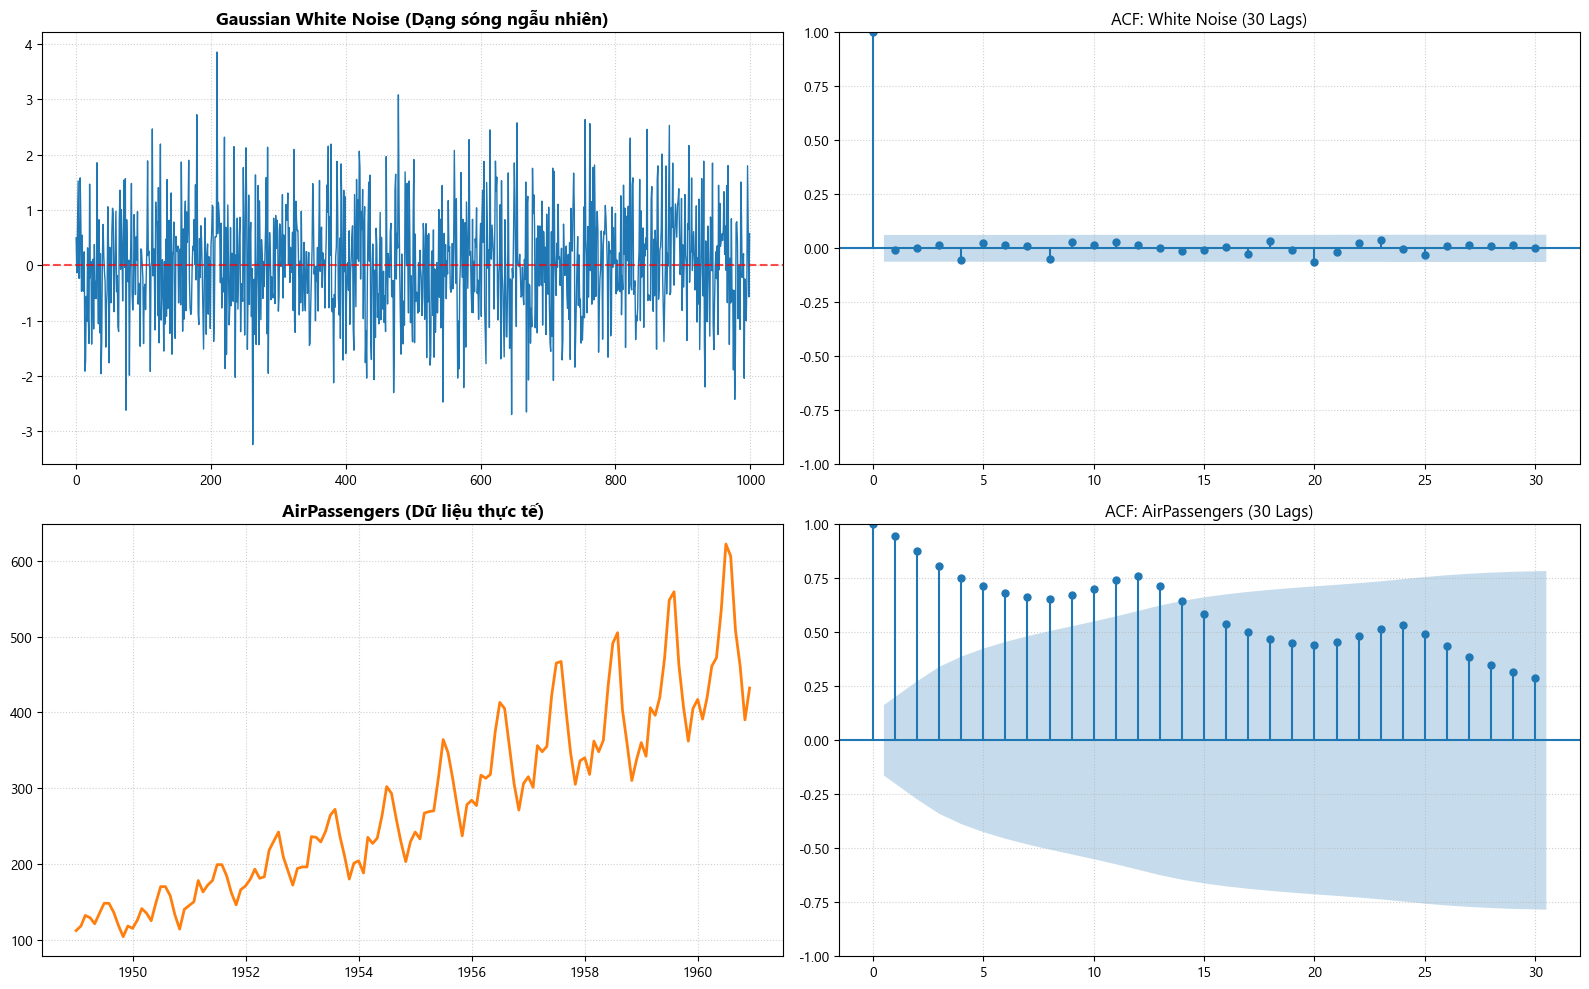

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(16, 10))

axes[0, 0].plot(wn_series.values, color="#1f77b4", lw=1)
axes[0, 0].axhline(0, color="red", linestyle="--", alpha=0.7)
axes[0, 0].set_title("Gaussian White Noise (Dạng sóng ngẫu nhiên)", fontsize=13, fontweight="bold")
axes[0, 0].grid(True, linestyle=":", alpha=0.6)

plot_acf(wn_series, lags=30, ax=axes[0, 1], alpha=0.05, title="ACF: White Noise (30 Lags)")
axes[0, 1].grid(True, linestyle=":", alpha=0.6)

axes[1, 0].plot(real_series.index, real_series.values, color="#ff7f0e", lw=2)
axes[1, 0].set_title("AirPassengers (Dữ liệu thực tế)", fontsize=13, fontweight="bold")
axes[1, 0].grid(True, linestyle=":", alpha=0.6)

plot_acf(real_series, lags=30, ax=axes[1, 1], alpha=0.05, title="ACF: AirPassengers (30 Lags)")
axes[1, 1].grid(True, linestyle=":", alpha=0.6)

plt.tight_layout()
fig_output = FIGURES_DIR / "bai2_white_noise_comparison.png"
plt.savefig(fig_output, dpi=300)
plt.show()


### Bước 4: Đoạn văn nhận xét đối chứng
1. Biểu đồ ACF của chuỗi White Noise có gần như toàn bộ các hệ số độ trễ nằm trọn bên trong dải tin cậy 95%, chứng minh các điểm dữ liệu hoàn toàn độc lập.
2. Ngược lại, biểu đồ ACF của chuỗi AirPassengers hiển thị các hệ số tự tương quan rất cao, suy giảm chậm và lặp lại các đỉnh chu kỳ tại lag 12.
3. Kiểm định Ljung-Box trên White Noise cho p-value lớn hơn 0.05 ($p=0.6571$), chấp nhận $H_0$ là nhiễu ngẫu nhiên thuần túy.
4. Đối với chuỗi AirPassengers, kiểm định Ljung-Box cho p-value xấp xỉ 0 tuyệt đối ($p < 10^{-177}$), bác bỏ $H_0$ và khẳng định dữ liệu chứa tín hiệu quy luật mạnh mẽ.
5. Do đó, White Noise hoàn toàn không thể dự báo được, trong khi AirPassengers rất lý tưởng để xây dựng các mô hình dự báo chuỗi thời gian.
